# 02 — Trực quan hóa & Phân tích Thuật toán Curriculum (Curriculum Walkthrough)

Notebook này phân tích và trực quan hóa từng bước trong logic cốt lõi của **Dynamic DDCL** trên tập dữ liệu huấn luyện:
1. **Centroid & Distance Determination**: Tính tâm cụm $\mu_c$ và chuẩn hóa khoảng cách Euclidean $\hat{r}_i$.
2. **KDE Level Partition**: Ước lượng mật độ khoảng cách 1D và xác định các ranh giới phân nhóm.
3. **DDCL-Density vs DDCL-Point Scoring**: Phân tích thứ tự mẫu Dễ (Easy) đến Khó (Hard).
4. **Self-Paced Learning (SPL) Pace Decision**: Cơ chế lọc batch theo loss và tiến hóa của ngưỡng $\lambda$.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

from dddcl.data.hf import load_dataset_from_release
from dddcl.data.splits import load_split
from dddcl.curriculum.geometry import compute_geometry
from dddcl.curriculum.partition import partition_by_class, kde_level_partition_v1
from dddcl.curriculum.scoring import create_curriculum
from dddcl.training.pace import compute_pace_decision, update_lambda

# Nạp dữ liệu Haberman và split seed 0
root = Path.cwd().resolve()
while not (root / 'requirements.in').exists() and root != root.parent:
    root = root.parent
release_dir = root / 'hf_release'
split_file = root / 'outputs' / 'splits' / 'paper_interpretation_clean_v1' / 'haberman' / 'seed_0.json'

bundle = load_dataset_from_release(release_dir, 'haberman')
split = load_split(split_file, bundle=bundle)

df = bundle.frame.set_index(bundle.row_id_column)
train_df = df.loc[split.train_ids]
X_train = train_df[bundle.feature_columns].values
y_train = train_df[bundle.label_column].values

print(f'Đã nạp tập train Haberman (N={len(X_train)}, đặc trưng={bundle.feature_columns})')


Đã nạp tập train Haberman (N=213, đặc trưng=['age', 'operation_year', 'positive_axillary_nodes'])


## 1. Xác định tâm cụm và Khoảng cách chuẩn hóa

- Với mỗi lớp $c$, tâm cụm $\mu_c$ được tính bằng trung bình cộng giải tích: $\mu_c = \frac{1}{|X_c|} \sum_{x \in X_c} x$.
- Khoảng cách Euclidean: $r_i = \|x_i - \mu_c\|_2$.
- Chuẩn hóa khoảng cách theo lớp: $\hat{r}_i = \frac{r_i}{\sqrt{\sum_{j \in X_c} r_j^2}}$.


In [2]:
geom = compute_geometry(X_train, y_train)

print('--- Tọa độ tâm cụm từng lớp ---')
for c, mu in geom.centroids.items():
    meaning = bundle.label_meanings.get(str(c), f'Class {c}')
    print(f'Lớp {c} ({meaning}): {mu.round(3)}')

# Thống kê khoảng cách chuẩn hóa
dist_df = pd.DataFrame({
    'label': y_train,
    'raw_distance': geom.raw_distances,
    'normalized_distance': geom.normalized_distances
})

summary_geom = dist_df.groupby('label').agg({
    'raw_distance': ['count', 'mean', 'std', 'max'],
    'normalized_distance': ['mean', 'std', 'max']
})
print('\n--- Thống kê khoảng cách theo lớp ---')
print(summary_geom.round(4))


--- Tọa độ tâm cụm từng lớp ---
Lớp 0 (survived_5_years_or_longer): [51.808 63.083  3.173]
Lớp 1 (died_within_5_years): [54.158 62.982  7.368]

--- Thống kê khoảng cách theo lớp ---
      raw_distance                           normalized_distance          \
             count     mean     std      max                mean     std   
label                                                                      
0              156  11.6549  6.7231  43.0615              0.0694  0.0400   
1               57  12.5010  6.0536  29.7576              0.1194  0.0578   

               
          max  
label          
0      0.2564  
1      0.2842  


## 2. Ước lượng Mật độ KDE và Phân chia Quantile

Thuật toán `kde_level_partition_v1` ước lượng hàm mật độ xác suất của khoảng cách chuẩn hóa bằng Gaussian KDE, sau đó cắt các mức mật độ ngang đều đặn từ $0$ đến đỉnh $D_{\text{peak}}$ để xác định các ranh giới phân nhóm.


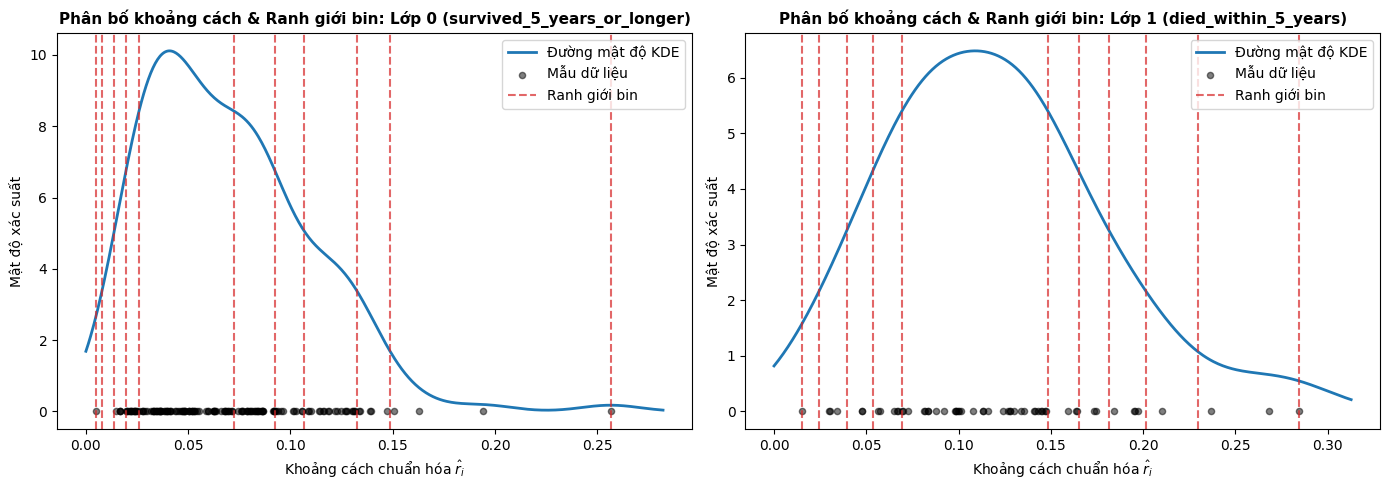

Số bin tạo ra cho từng lớp: {0: 10, 1: 10}


In [3]:
partition = partition_by_class(geom.normalized_distances, y_train, n_levels=6)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, c in zip(axes, [0, 1]):
    mask = (y_train == c)
    dists = geom.normalized_distances[mask]
    bounds = partition.boundaries[c]
    
    # KDE curve
    kde = gaussian_kde(dists)
    grid = np.linspace(0, max(dists) * 1.1, 500)
    density = kde.evaluate(grid)
    
    ax.plot(grid, density, label='Đường mật độ KDE', color='#1f77b4', lw=2)
    ax.scatter(dists, np.zeros_like(dists), color='black', alpha=0.5, s=20, label='Mẫu dữ liệu')
    
    # Vẽ các đường ranh giới bin
    for b_idx, b in enumerate(bounds):
        label_bound = 'Ranh giới bin' if b_idx == 0 else None
        ax.axvline(b, color='#d62728', linestyle='--', alpha=0.7, label=label_bound)
    
    meaning = bundle.label_meanings.get(str(c), f'Class {c}')
    ax.set_title(f'Phân bố khoảng cách & Ranh giới bin: Lớp {c} ({meaning})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Khoảng cách chuẩn hóa $\hat{r}_i$')
    ax.set_ylabel('Mật độ xác suất')
    ax.legend()

plt.tight_layout()
plt.show()

print('Số bin tạo ra cho từng lớp:', partition.n_bins_per_class)


## 3. So sánh Cơ chế Xếp thứ tự: DDCL-Density vs DDCL-Point

- **DDCL-Point**: Xếp các mẫu hoàn toàn theo khoảng cách chuẩn hóa $\hat{r}_i$ tăng dần. Mẫu ở gần tâm cụm được coi là DỄ NHẤT, mẫu ở xa rìa được coi là KHÓ NHẤT.
- **DDCL-Density**: Xếp các mẫu theo mật độ của nhóm/quantile. Nhóm nào tập trung đông mẫu nhất (mật độ cao nhất) được học TRƯỚC, nhóm thưa thớt (ngoại lai hoặc hiếm) học SAU.


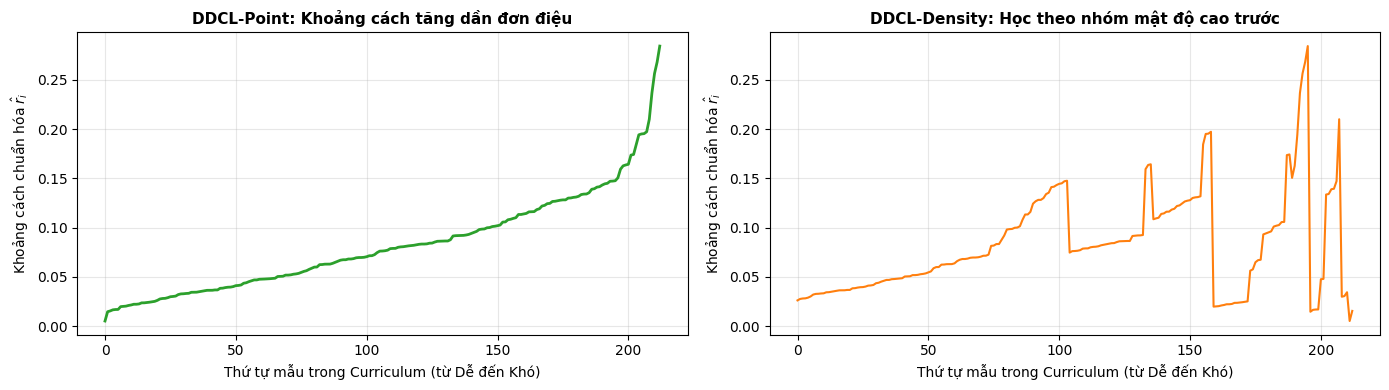

Mẫu dễ nhất của DDCL-Point: haberman:000147 (dist=0.0051)
Mẫu khó nhất của DDCL-Point: haberman:000305 (dist=0.2842)


In [4]:
curriculum_point = create_curriculum(
    strategy='ddcl_point',
    sample_ids=split.train_ids,
    normalized_distances=geom.normalized_distances,
    bin_assignments=partition.bin_assignments,
)

curriculum_density = create_curriculum(
    strategy='ddcl_density',
    sample_ids=split.train_ids,
    normalized_distances=geom.normalized_distances,
    bin_assignments=partition.bin_assignments,
)

# Lấy khoảng cách theo thứ tự học
dists_point = [geom.normalized_distances[split.train_ids.index(sid)] for sid in curriculum_point.ordered_train_ids]
dists_density = [geom.normalized_distances[split.train_ids.index(sid)] for sid in curriculum_density.ordered_train_ids]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(dists_point, color='#2ca02c', lw=2)
ax1.set_title('DDCL-Point: Khoảng cách tăng dần đơn điệu', fontsize=11, fontweight='bold')
ax1.set_xlabel('Thứ tự mẫu trong Curriculum (từ Dễ đến Khó)')
ax1.set_ylabel('Khoảng cách chuẩn hóa $\hat{r}_i$')
ax1.grid(True, alpha=0.3)

ax2.plot(dists_density, color='#ff7f0e', lw=1.5)
ax2.set_title('DDCL-Density: Học theo nhóm mật độ cao trước', fontsize=11, fontweight='bold')
ax2.set_xlabel('Thứ tự mẫu trong Curriculum (từ Dễ đến Khó)')
ax2.set_ylabel('Khoảng cách chuẩn hóa $\hat{r}_i$')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Mẫu dễ nhất của DDCL-Point:', curriculum_point.ordered_train_ids[0], f'(dist={dists_point[0]:.4f})')
print('Mẫu khó nhất của DDCL-Point:', curriculum_point.ordered_train_ids[-1], f'(dist={dists_point[-1]:.4f})')


## 4. Mô phỏng Quyết định Self-Paced Learning (SPL) theo Batch

Trong mỗi epoch, SPL đánh giá loss trung bình $L_b$ của từng batch:
- Nếu $L_b < \lambda$: Batch được xếp vào tập **Easy** $\mathcal{E}$ và được sắp xếp từ loss thấp đến cao để huấn luyện.
- Nếu $L_b \ge \lambda$: Batch bị xếp vào tập **Hard** $\mathcal{H}$ và bị bỏ qua tạm thời.
- Ngưỡng $\lambda$ khởi đầu từ $0.4$, tăng dần theo hệ số $1.1$ sau mỗi epoch và đạt mức trần $0.6$.


Loss các batch: [0.25, 0.55, 0.38, 0.72, 0.41, 0.3]
Ngưỡng lambda = 0.4
-> Easy batches (Loss < 0.4): [0, 5, 2] (Losses: [0.25, 0.3, 0.38])
-> Hard batches (Loss >= 0.4): [4, 1, 3] (Losses: [0.41, 0.55, 0.72])


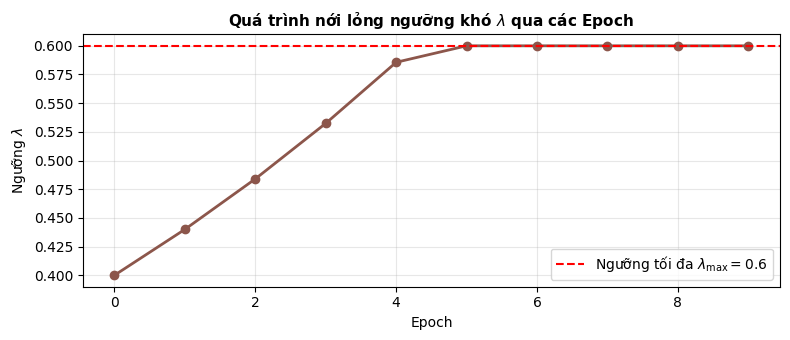

In [5]:
# Giả lập 6 batch với loss khác nhau trong epoch đầu (lambda = 0.4)
mock_batch_losses = [0.25, 0.55, 0.38, 0.72, 0.41, 0.30]
lambda_current = 0.4

decision = compute_pace_decision(mock_batch_losses, lambda_val=lambda_current)
print(f'Loss các batch: {mock_batch_losses}')
print(f'Ngưỡng lambda = {lambda_current}')
print(f'-> Easy batches (Loss < {lambda_current}): {decision.ordered_easy_batches} (Losses: {[mock_batch_losses[i] for i in decision.ordered_easy_batches]})')
print(f'-> Hard batches (Loss >= {lambda_current}): {decision.ordered_hard_batches} (Losses: {[mock_batch_losses[i] for i in decision.ordered_hard_batches]})')

# Mô phỏng sự tăng trưởng của ngưỡng lambda qua 10 epoch
lambdas = [lambda_current]
for ep in range(1, 10):
    lambda_current = update_lambda(lambda_current, lambda_max=0.6, growth=1.1)
    lambdas.append(lambda_current)

plt.figure(figsize=(8, 3.5))
plt.plot(range(10), lambdas, marker='o', color='#8c564b', lw=2)
plt.axhline(0.6, color='red', linestyle='--', label='Ngưỡng tối đa $\lambda_{\max}=0.6$')
plt.title('Quá trình nới lỏng ngưỡng khó $\lambda$ qua các Epoch', fontsize=11, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Ngưỡng $\lambda$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Kết luận Phase C

- Đã xác thực toàn bộ logic toán học: Centroid Euclidean, Normalization $L_2$, Gaussian KDE partition, Density/Point scoring, và SPL PaceDecision.
- Các hàm đều là hàm thuần túy (*pure functions*), độc lập với gradient optimizer, được kiểm thử tính tay với 100% test pass.
- Sẵn sàng tiến vào **Phase D (Xây dựng PyTorch Training Loop, Checkpoints & Metrics)**.
